# Kalibrasyon + SHAP - Risk Skorlamasi

Plandan: *olasilik ureten bir modeli kalibrasyon gostermeden savunamazsin; SHAP, M3'un kara kutu bosluguna en ucuz cevap.*

In [1]:
# === COLAB KURULUM ===  (yerelde calistirinca atlanir)
import os, sys
IN_COLAB = 'google.colab' in sys.modules
if IN_COLAB and not os.path.exists('/content/QuakeMind'):
    !git clone --depth 1 https://github.com/UtBird/QuakeMind.git /content/QuakeMind
if IN_COLAB:
    %cd /content/QuakeMind/model_benchmarks/05_risk_skoru
    %pip install -q catboost xgboost lightgbm shap scikit-learn
print('cwd:', os.getcwd())

cwd: /home/utku/Desktop/QuakeMindLD/QuakeMind/model_benchmarks/05_risk_skoru


## 1. Veri + model

In [2]:
import sys, warnings; warnings.filterwarnings('ignore')
from pathlib import Path; sys.path.insert(0, str(Path.cwd()))
import numpy as np, pandas as pd, common_preprocessing as cp
X, y, df_main = cp.load_dataset()
splits = cp.walk_forward_splits(len(X), 5)

In [3]:
from catboost import CatBoostClassifier
from sklearn.calibration import calibration_curve
from sklearn.metrics import brier_score_loss
tr, te = splits[-1]
model = CatBoostClassifier(iterations=800, depth=8, learning_rate=0.03, verbose=False, random_seed=42)
model.fit(X.iloc[tr], y.iloc[tr])
prob = model.predict_proba(X.iloc[te])[:,1]; yte = y.iloc[te].values

## 2. Kalibrasyon egrisi + Brier

Brier: 0.2614


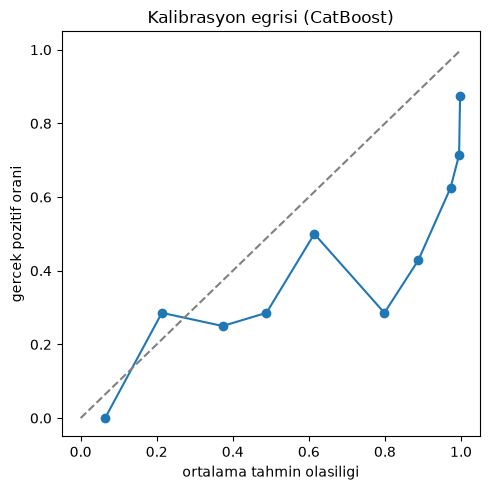

In [4]:
import matplotlib.pyplot as plt
frac_pos, mean_pred = calibration_curve(yte, prob, n_bins=10, strategy='quantile')
print('Brier:', round(brier_score_loss(yte, prob), 4))
fig, ax = plt.subplots(figsize=(5,5))
ax.plot(mean_pred, frac_pos, 'o-'); ax.plot([0,1],[0,1],'--',c='gray')
ax.set_xlabel('ortalama tahmin olasiligi'); ax.set_ylabel('gercek pozitif orani')
ax.set_title('Kalibrasyon egrisi (CatBoost)')
import os; os.makedirs('results', exist_ok=True)
plt.tight_layout(); plt.savefig('results/calibration_curve.png', dpi=150); plt.show()

## 3. SHAP ozet

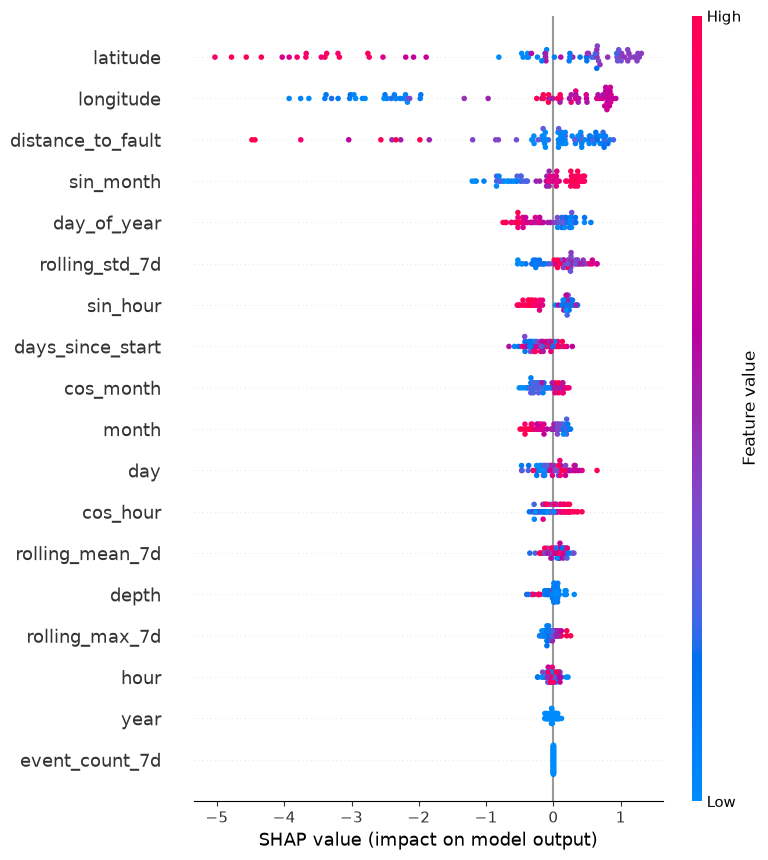

In [5]:
import shap
expl = shap.TreeExplainer(model)
sv = expl.shap_values(X.iloc[te])
shap.summary_plot(sv, X.iloc[te], show=False)
import matplotlib.pyplot as plt; plt.tight_layout(); plt.savefig('results/shap_summary.png', dpi=150, bbox_inches='tight'); plt.show()

## 4. Ozellik onem siralamasi (ortalama |SHAP|)

In [6]:
imp = pd.DataFrame({'feature': X.columns, 'mean_abs_shap': np.abs(sv).mean(0)}).sort_values('mean_abs_shap', ascending=False)
imp

,feature,mean_abs_shap
0,latitude,1.380128
1,longitude,1.340356
17,distance_to_fault,0.747201
13,sin_month,0.394982
11,day_of_year,0.310783
4,rolling_std_7d,0.270002
15,sin_hour,0.259194
12,days_since_start,0.228676
14,cos_month,0.197225
8,month,0.193238
